<a href="https://colab.research.google.com/github/seanyi-creator/ba-305-project/blob/main/04_rents_charts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 — Rents: cleaning + charts (Workstream 3)
**Team A7 · Descriptive question**

> Between 2004–06 and 2014–16, did 2-bedroom asking rents rise faster in San Francisco neighborhoods that started in the cheapest third than in those that started in the priciest third, and did listings in those cheaper neighborhoods shift toward studios and 1-bedrooms?

**Data:** TidyTuesday 2022-07-05 `rent.csv` (Craigslist listings, 2000–2018), loaded from the raw GitHub URL so this notebook runs in a fresh Colab runtime.

**Proxy note:** "Lower-income" is measured by a proxy: neighborhoods in the cheapest third of median 2-bedroom rent in 2004–06. The data has no income column, so this is a stand-in for income, not income itself.

Sections:
1. Setup
2. Rent cleaning
3. Cleaning summary (how many listings/neighborhoods survive)
4. Chart 1: dumbbell chart (headline)
5. Chart 2: boxplots by third × period
6. Chart 3: bedroom mix by third × period
7. Chart 4: robustness check (rent per bedroom, means vs. medians, citywide index)
8. Findings in plain words

In [1]:
# --- Shipra: setup — import libraries and set chart style ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)

# One fixed color per third, used in every chart so a group always looks the same
THIRD_COLORS = {"cheapest": "#2a78d6",   # blue
                "middle":   "#eb6834",   # orange
                "priciest": "#1baf7a"}   # aqua
THIRDS = ["cheapest", "middle", "priciest"]

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
})

In [2]:
# --- Shipra: load and clean the rent data
# Every rule here is a decision we defend in the report (Data section).

RENT_URL = ("https://raw.githubusercontent.com/rfordatascience/tidytuesday/"
            "main/data/2022/2022-07-05/rent.csv")

# Periods: single years are too thin (e.g. ~80 SF 2-bed listings in 2010), so we pool 3 years.
PERIODS = {"2004-06": (2004, 2006),   # starting point
           "2011-13": (2011, 2013),   # midpoint
           "2014-16": (2014, 2016)}   # end point
EARLY, MID, LATE = "2004-06", "2011-13", "2014-16"
MIN_LISTINGS = 30   # a neighborhood needs >= 30 two-bedroom listings in EACH period


def assign_period(year):
    """Map a year to its pooled period label, or None if outside all periods."""
    for label, (start, end) in PERIODS.items():
        if start <= year <= end:
            return label
    return None


def get_rent_data():
    """Return (listings, nhoods).

    listings: one row per SF Craigslist listing in a kept neighborhood and period,
              with columns year, period, nhood, price, beds, third.
    nhoods:   one row per kept neighborhood with its median 2-bed rent in each
              period, growth from 2004-06 to 2014-16, and its starting third.
    """
    raw = pd.read_csv(RENT_URL, usecols=["year", "nhood", "city", "price", "beds"])

    # 1. San Francisco only
    sf = raw[raw["city"] == "san francisco"].copy()

    # 2. Drop the generic label "san francisco": it is not a neighborhood
    sf = sf[sf["nhood"] != "san francisco"]

    # 3. Keep only listings in one of the three periods, with a price and bed count
    sf["period"] = sf["year"].apply(assign_period)
    sf = sf.dropna(subset=["period", "price", "beds"])

    # 4. The 30-listing rule, counted on 2-bedroom listings in every period
    two_bed = sf[sf["beds"] == 2]
    counts = two_bed.groupby(["nhood", "period"]).size().unstack(fill_value=0)
    counts = counts.reindex(columns=list(PERIODS), fill_value=0)
    keep = counts[(counts >= MIN_LISTINGS).all(axis=1)].index

    sf = sf[sf["nhood"].isin(keep)].copy()
    two_bed = two_bed[two_bed["nhood"].isin(keep)]

    # 5. Median 2-bed rent per neighborhood per period (median: robust to odd listings)
    nhoods = (two_bed.groupby(["nhood", "period"])["price"].median()
                     .unstack()[list(PERIODS)])
    nhoods["growth_pct"] = (nhoods[LATE] / nhoods[EARLY] - 1) * 100

    # 6. Thirds by STARTING (2004-06) rent: our proxy for lower- vs higher-income
    nhoods["third"] = pd.qcut(nhoods[EARLY], 3, labels=THIRDS).astype(str)
    nhoods = nhoods.sort_values(EARLY)

    sf = sf.merge(nhoods[["third"]], left_on="nhood", right_index=True)
    return sf, nhoods


listings, nhoods = get_rent_data()
print(f"{len(listings):,} listings in {nhoods.shape[0]} neighborhoods kept")

40,004 listings in 26 neighborhoods kept


In [3]:
# Shipra: cleaning summary — report how much data survives each rule ---
raw = pd.read_csv(RENT_URL, usecols=["year", "nhood", "city", "price", "beds"])
sf_all = raw[raw["city"] == "san francisco"]

summary = pd.Series({
    "All Bay Area listings": len(raw),
    "San Francisco listings": len(sf_all),
    "SF neighborhood labels": sf_all["nhood"].nunique(),
    "Neighborhoods passing the 30-listing rule": nhoods.shape[0],
    "Listings used (kept neighborhoods, 3 periods)": len(listings),
})
print(summary.to_string())

print("\nListings per year in SF (why we pool years):")
print(sf_all.groupby("year").size().to_string())

print("\nNeighborhoods per third:")
print(nhoods["third"].value_counts().reindex(THIRDS).to_string())

All Bay Area listings                            200796
San Francisco listings                            55730
SF neighborhood labels                               47
Neighborhoods passing the 30-listing rule            26
Listings used (kept neighborhoods, 3 periods)     40004

Listings per year in SF (why we pool years):
year
2000       11
2001      431
2002      148
2003      521
2004    19654
2005     2988
2006     5187
2007     2129
2008      930
2009      347
2010      257
2011     4370
2012     6948
2013     1888
2014     1324
2015     3109
2016     4191
2017      530
2018      767

Neighborhoods per third:
third
cheapest    9
middle      9
priciest    8


In [4]:
# Shipra: neighborhood table — median 2-bed rent per period and growth ---
nhoods.round(0)

period,2004-06,2011-13,2014-16,growth_pct,third
nhood,,,,,
excelsior / outer mission,1600.0,2100.0,2500.0,56.0,cheapest
ingleside,1600.0,2400.0,3086.0,93.0,cheapest
sea cliff,1600.0,2400.0,3100.0,94.0,cheapest
outer sunset,1650.0,2200.0,3000.0,82.0,cheapest
inner sunset,1695.0,2538.0,3350.0,98.0,cheapest
parkside,1700.0,2200.0,2800.0,65.0,cheapest
bayview,1700.0,1900.0,3295.0,94.0,cheapest
inner richmond,1712.0,2299.0,3295.0,92.0,cheapest
mission district,1780.0,2800.0,4295.0,141.0,cheapest


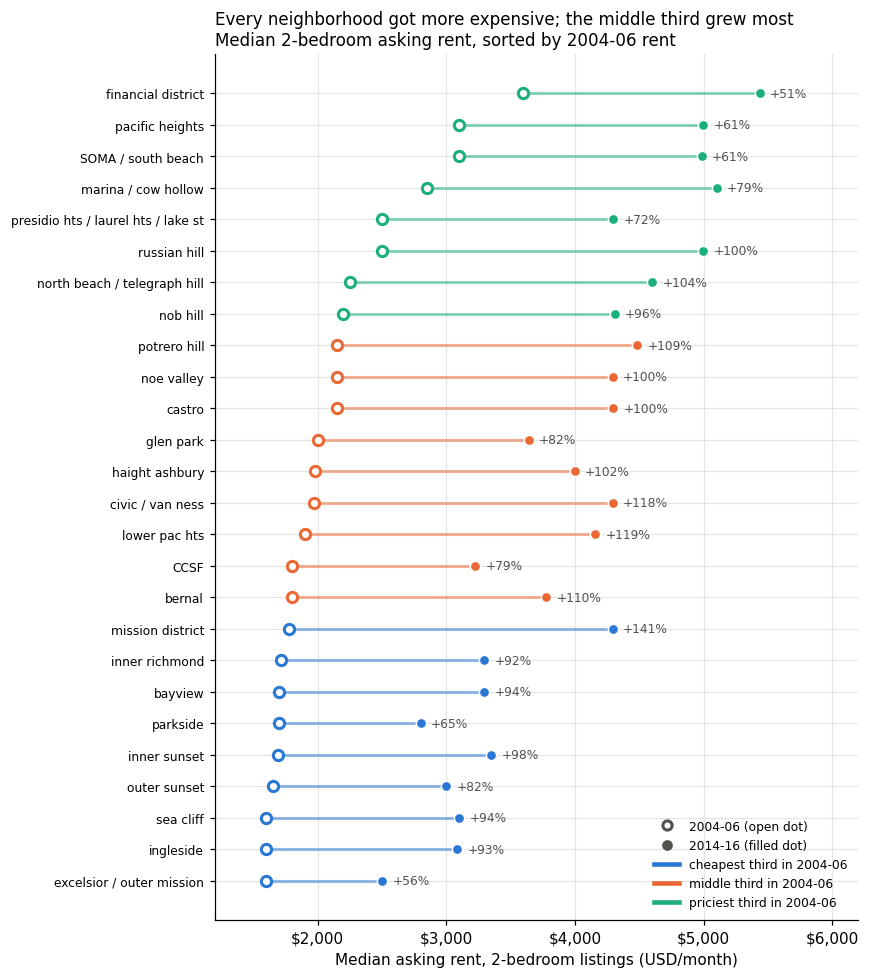

Median growth by third (%):
third
cheapest     93.0
middle      102.0
priciest     75.0


In [5]:
# Shipra: Chart 1 — dumbbell chart of 2-bed rent, 2004-06 vs 2014-16 (headline figure) ---
d = nhoods.sort_values(EARLY)
y = np.arange(len(d))

fig, ax = plt.subplots(figsize=(8, 9))
for i, (name, row) in enumerate(d.iterrows()):
    c = THIRD_COLORS[row["third"]]
    ax.plot([row[EARLY], row[LATE]], [i, i], color=c, linewidth=2, alpha=0.5, zorder=1)
    ax.scatter(row[EARLY], i, s=45, facecolor="white", edgecolor=c, linewidth=2, zorder=2)
    ax.scatter(row[LATE], i, s=45, color=c, edgecolor="white", linewidth=1, zorder=3)
    ax.text(row[LATE] + 80, i, f"+{row['growth_pct']:.0f}%", va="center",
            fontsize=8, color="#52514e")

ax.set_yticks(y)
ax.set_yticklabels(d.index, fontsize=8)
ax.set_xlabel("Median asking rent, 2-bedroom listings (USD/month)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlim(1200, 6200)

from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", linestyle="", markerfacecolor="white",
                  markeredgecolor="#52514e", markeredgewidth=2, label="2004-06 (open dot)"),
           Line2D([], [], marker="o", linestyle="", color="#52514e", label="2014-16 (filled dot)")]
handles += [Line2D([], [], color=THIRD_COLORS[t], linewidth=3,
                   label=f"{t} third in 2004-06") for t in THIRDS]
ax.legend(handles=handles, loc="lower right", fontsize=8, frameon=False)

ax.set_title("Every neighborhood got more expensive; the middle third grew most\n"
             "Median 2-bedroom asking rent, sorted by 2004-06 rent", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

growth_by_third = nhoods.groupby("third")["growth_pct"].median().reindex(THIRDS)
print("Median growth by third (%):")
print(growth_by_third.round(0).to_string())

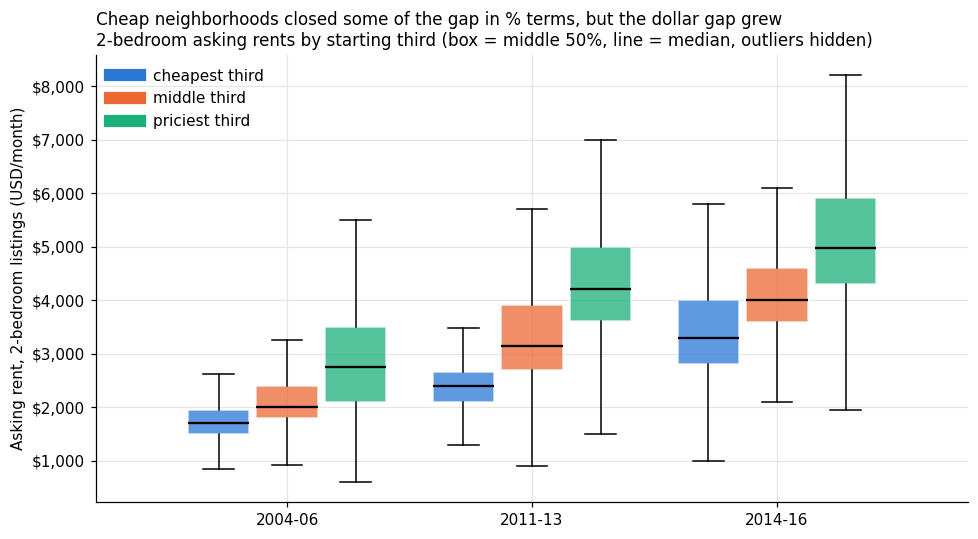

Median 2-bed rent by third and period:
period    2004-06  2011-13  2014-16
third                              
cheapest   1695.0   2390.0   3295.0
middle     2000.0   3150.0   4000.0
priciest   2750.0   4200.0   4971.0

Number of 2-bed listings in each box:
period    2004-06  2011-13  2014-16
third                              
cheapest     3027     1619      690
middle       1756      677      663
priciest     2911     1538     1010


In [6]:
# Shipra: Chart 2 — boxplots of 2-bed rent by third x period (spread, not just the middle) ---
two = listings[listings["beds"] == 2]
periods = list(PERIODS)

fig, ax = plt.subplots(figsize=(9, 5))
width = 0.25
for j, t in enumerate(THIRDS):
    data = [two[(two["third"] == t) & (two["period"] == p)]["price"] for p in periods]
    pos = np.arange(len(periods)) + (j - 1) * (width + 0.03)
    bp = ax.boxplot(data, positions=pos, widths=width, patch_artist=True,
                    showfliers=False, medianprops=dict(color="black", linewidth=1.5))
    for box in bp["boxes"]:
        box.set_facecolor(THIRD_COLORS[t]); box.set_alpha(0.75); box.set_edgecolor("white")
    ax.plot([], [], color=THIRD_COLORS[t], linewidth=8, label=f"{t} third")

ax.set_xticks(np.arange(len(periods)))
ax.set_xticklabels(periods)
ax.set_ylabel("Asking rent, 2-bedroom listings (USD/month)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.legend(frameon=False, loc="upper left")
ax.set_title("Cheap neighborhoods closed some of the gap in % terms, but the dollar gap grew\n"
             "2-bedroom asking rents by starting third (box = middle 50%, line = median, "
             "outliers hidden)", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

print("Median 2-bed rent by third and period:")
print(two.groupby(["third", "period"])["price"].median().unstack()
         .reindex(THIRDS).round(0).to_string())
print("\nNumber of 2-bed listings in each box:")
print(two.groupby(["third", "period"]).size().unstack().reindex(THIRDS).to_string())

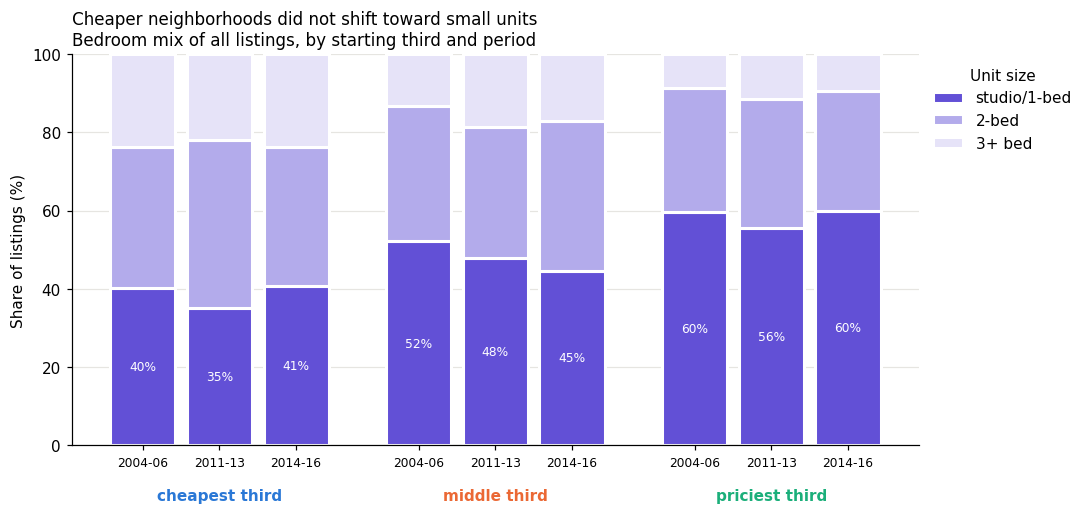

Share of studio/1-bed listings (%):
          2004-06  2011-13  2014-16
cheapest     40.1     35.0     40.6
middle       52.1     47.9     44.6
priciest     59.6     55.5     60.0


In [7]:
# Shipra: Chart 3 — bedroom mix (studio/1, 2, 3+) by third x period ---
mix = listings.copy()
mix["size"] = pd.cut(mix["beds"], bins=[-1, 1, 2, 100], labels=["studio/1-bed", "2-bed", "3+ bed"])
share = (mix.groupby(["third", "period"])["size"].value_counts(normalize=True)
            .unstack() * 100)
share = share.reindex(pd.MultiIndex.from_product([THIRDS, list(PERIODS)]))

SIZE_COLORS = {"studio/1-bed": "#6250d6", "2-bed": "#b3abeb", "3+ bed": "#e6e3f8"}
fig, ax = plt.subplots(figsize=(10, 4.8))
x, labels, gap = [], [], 0
for i, (t, p) in enumerate(share.index):
    if i and i % 3 == 0:
        gap += 0.6
    x.append(i + gap); labels.append(p)
bottom = np.zeros(len(share))
for s in ["studio/1-bed", "2-bed", "3+ bed"]:
    vals = share[s].values
    ax.bar(x, vals, bottom=bottom, color=SIZE_COLORS[s], edgecolor="white",
           linewidth=2, width=0.85, label=s)
    if s == "studio/1-bed":
        for xi, v in zip(x, vals):
            ax.text(xi, v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8)
    bottom += vals

ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
for k, t in enumerate(THIRDS):
    ax.text(np.mean(x[k*3:k*3+3]), -14, f"{t} third", ha="center",
            fontsize=10, color=THIRD_COLORS[t], fontweight="bold")
ax.set_ylim(0, 100); ax.set_ylabel("Share of listings (%)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0), title="Unit size")
ax.set_title("Cheaper neighborhoods did not shift toward small units\n"
             "Bedroom mix of all listings, by starting third and period", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

print("Share of studio/1-bed listings (%):")
print(share["studio/1-bed"].unstack().round(1).to_string())

Median neighborhood growth 2004-06 -> 2014-16 (%), by measure:
          2-bed median (main)  rent per bedroom  2-bed mean
third                                                      
cheapest                 93.0              79.0        86.0
middle                  102.0              89.0       103.0
priciest                 75.0              82.0        68.0

Citywide median 2-bed rent: $2,000 -> $4,250 (+112%)
Each third's growth relative to citywide (growth / citywide growth):
third
cheapest    0.83
middle      0.91
priciest    0.67


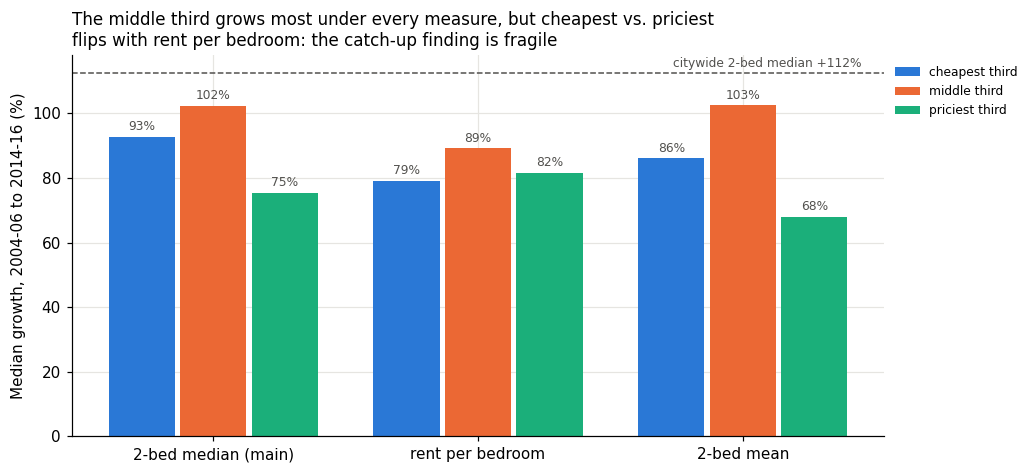

In [8]:
# Shipra: Chart 4 — robustness check: does the conclusion survive other measures? ---
# (a) Rent per bedroom, using ALL listings with 1+ bedrooms (not only 2-beds)
# (b) Means instead of medians for 2-bed rent
# (c) Each third's growth indexed to the citywide median growth (separates
#     neighborhood change from citywide change: the third variable)

pb = listings[listings["beds"] >= 1].copy()
pb["rent_per_bed"] = pb["price"] / pb["beds"]
per_bed = pb.groupby(["nhood", "period"])["rent_per_bed"].median().unstack()
per_bed_growth = (per_bed[LATE] / per_bed[EARLY] - 1) * 100

two = listings[listings["beds"] == 2]
means = two.groupby(["nhood", "period"])["price"].mean().unstack()
mean_growth = (means[LATE] / means[EARLY] - 1) * 100

city = two.groupby("period")["price"].median()
city_growth = (city[LATE] / city[EARLY] - 1) * 100

robust = pd.DataFrame({
    "2-bed median (main)": nhoods["growth_pct"],
    "rent per bedroom":    per_bed_growth,
    "2-bed mean":          mean_growth,
    "third":               nhoods["third"],
})
table = robust.groupby("third").median().reindex(THIRDS)
print("Median neighborhood growth 2004-06 -> 2014-16 (%), by measure:")
print(table.round(0).to_string())
print(f"\nCitywide median 2-bed rent: ${city[EARLY]:,.0f} -> ${city[LATE]:,.0f} "
      f"(+{city_growth:.0f}%)")
print("Each third's growth relative to citywide (growth / citywide growth):")
print((table["2-bed median (main)"] / city_growth).round(2).to_string())

fig, ax = plt.subplots(figsize=(9.5, 4.4))
measures = list(table.columns)
w = 0.25
for j, t in enumerate(THIRDS):
    vals = table.loc[t].values
    pos = np.arange(len(measures)) + (j - 1) * (w + 0.02)
    ax.bar(pos, vals, width=w, color=THIRD_COLORS[t], label=f"{t} third")
    for xp, v in zip(pos, vals):
        ax.text(xp, v + 2, f"{v:.0f}%", ha="center", fontsize=8, color="#52514e")
ax.axhline(city_growth, color="#52514e", linestyle="--", linewidth=1)
ax.text(len(measures) - 0.55, city_growth + 2, f"citywide 2-bed median +{city_growth:.0f}%",
        ha="right", fontsize=8, color="#52514e")
ax.set_xticks(np.arange(len(measures))); ax.set_xticklabels(measures)
ax.set_ylabel("Median growth, 2004-06 to 2014-16 (%)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
ax.set_title("The middle third grows most under every measure, but cheapest vs. priciest\n"
             "flips with rent per bedroom: the catch-up finding is fragile",
             loc="left", fontsize=11)
plt.tight_layout()
plt.show()

## Findings in plain words

- **Data kept:** 26 of 47 SF neighborhood labels pass the 30-listing rule in all three periods (9 cheapest, 9 middle, 8 priciest), about 40,000 listings.
- **Rent growth:** 2-bedroom rents rose in every kept neighborhood. The cheapest third grew faster than the priciest (median +93% vs. +75%), but the **middle third grew fastest** (+102%). The Mission (+141%) is the biggest single jump.
- **Gap:** in percentage terms the cheap neighborhoods caught up somewhat, but in dollars the gap between the cheapest and priciest thirds grew (about $1,050 → $1,680 a month).
- **Unit mix:** the share of studios and 1-bedrooms in the cheapest third did not move (40% → 41%). The "smaller units" half of the gentrification story **does not show up**.
- **Robustness:** the middle third grows most under all three measures. But with rent per bedroom the cheapest third (+79%) falls slightly behind the priciest (+82%), so "cheap neighborhoods rose faster" is a fragile result, not a firm one.
- **Citywide trend:** the citywide 2-bed median rose +112%, more than any third. Part of that comes from listings shifting toward pricier neighborhoods over time, not only from rents rising.

**Limitations:** neighborhood labels are chosen by the poster (e.g. Sea Cliff, a wealthy area, lands in the "cheapest" third; "CCSF" is a college, not a neighborhood); Craigslist asking rents are not signed leases; the thirds are an income *proxy*; only neighborhoods with 30+ listings in every period survive (survivorship); years are very uneven (2004 alone has ~19,700 SF listings).

**Overall summary:** Between 2004–06 and 2014–16, San Francisco's cheapest neighborhoods saw 2-bedroom rents rise somewhat faster than its priciest ones but slower than the middle third, and their mix of small units did not change, so the usual gentrification pattern only partly appears in the rent data.